In [1]:

# IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine-learning models
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Evaluation metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# XGBoost
from xgboost import XGBRegressor

# Statistical models
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# File location
file_path = r"C:\Users\suraj\Downloads\1C. Dashboard_data_Henderson.xlsx"

# Load the Main worksheet
df = pd.read_excel(file_path, sheet_name="Main")

In [3]:
# Display first 5 rows
print("First 5 rows:")
display(df.head())

First 5 rows:


,Site,Date,Time,Parameter,Value
0,HEN,2020-11-06,01:00:00,BC(370),-10.87
1,HEN,2018-09-29,11:00:00,BC(370),-10.83
2,HEN,2017-09-17,04:00:00,BC(370),-10.50
3,HEN,2018-05-22,05:00:00,BC(370),-10.50
4,HEN,2020-04-17,23:00:00,BC(880),-10.50


In [4]:
# Check dataset size
print("\nDataset shape:")
print(df.shape)


Dataset shape:
(1048208, 5)


In [5]:
# Check column names
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['Site', 'Date', 'Time', 'Parameter', 'Value']


In [6]:
# Check data types
print("\nData types:")
print(df.dtypes)


Data types:
Site                    str
Date         datetime64[us]
Time                 object
Parameter               str
Value               float64
dtype: object


In [7]:
# Check general information
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1048208 entries, 0 to 1048207
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype         
---  ------     --------------    -----         
 0   Site       1048208 non-null  str           
 1   Date       1048208 non-null  datetime64[us]
 2   Time       1048208 non-null  object        
 3   Parameter  1048208 non-null  str           
 4   Value      1048208 non-null  float64       
dtypes: datetime64[us](1), float64(1), object(1), str(2)
memory usage: 46.2+ MB


In [8]:
#  Check all available parameters
print("Number of unique parameters:")
print(df['Parameter'].nunique())

print("\nAvailable parameters:")
print(sorted(df['Parameter'].unique()))

Number of unique parameters:
11

Available parameters:
['AQI', 'BC(370)', 'BC(880)', 'NO', 'NO2', 'NOx', 'PM10', 'RH', 'Temp', 'WD', 'WS']


In [9]:
# Count observations for each parameter

parameter_counts = df['Parameter'].value_counts()

print("Number of records for each parameter:")
display(parameter_counts)

Number of records for each parameter:


Parameter
PM10       143889
NO2        140510
WS         134623
Temp       133530
RH         133529
NO         132078
NOx        123639
BC(880)     50743
BC(370)     48841
WD           4325
AQI          2501
Name: count, dtype: int64

In [10]:
# Check date range

print("Earliest date:", df['Date'].min())
print("Latest date:", df['Date'].max())

Earliest date: 2006-01-01 00:00:00
Latest date: 2023-02-28 00:00:00


                                                PREPROCESSING

In [12]:
# Selecting parameters
VARS = ["PM10", "NO2", "Temp", "RH", "WS"]
df_sel = df[df["Parameter"].isin(VARS)].copy()
df_sel["Parameter"].value_counts()

Parameter
PM10    143889
NO2     140510
WS      134623
Temp    133530
RH      133529
Name: count, dtype: int64

In [13]:
# Convert the Time column to a time duration (e.g. 05:00:00 -> 5 hours)
time_part = pd.to_timedelta(df_sel["Time"].astype(str))

# Add the date and the time together into a new column called "datetime"
df_sel["datetime"] = df_sel["Date"] + time_part

# Check it worked
df_sel[["Date", "Time", "datetime"]].head()

,Date,Time,datetime
9,2018-02-13,01:00:00,2018-02-13 01:00:00
10,2018-08-05,14:00:00,2018-08-05 14:00:00
15,2017-11-14,16:00:00,2017-11-14 16:00:00
16,2019-09-23,01:00:00,2019-09-23 01:00:00
21,2019-01-15,01:00:00,2019-01-15 01:00:00


In [15]:
# Which parameters and years are the duplicates in?
# Keep only the duplicate rows, then count them by parameter and year
dups = df_sel[dup_mask]
dups.groupby(["Parameter", dups["datetime"].dt.year]).size()

Parameter  datetime
NO2        2011        16864
dtype: int64

In [14]:
# Find duplicate readings
# Mark every row where the same datetime AND parameter appear more than once
# keep=False marks ALL copies of a duplicate (not just the second one), so we can compare them
dup_mask = df_sel.duplicated(subset=["datetime", "Parameter"], keep=False)

# Count how many rows are duplicates (True counts as 1, False as 0)
dup_mask.sum()

np.int64(16864)

In [16]:
# Compare the two values in each duplicate pair
# For each datetime + parameter, show the smaller and larger of the two values
pairs = dups.groupby(["datetime", "Parameter"])["Value"].agg(["min", "max"])
pairs.head(10)

,,min,max
datetime,Parameter,,
2011-01-01 00:00:00,NO2,3.41484,8.978285
2011-01-01 01:00:00,NO2,4.25751,15.442699
2011-01-01 02:00:00,NO2,2.49588,8.053333
2011-01-01 03:00:00,NO2,1.04140,3.005621
2011-01-01 04:00:00,NO2,0.86533,2.887037
2011-01-01 05:00:00,NO2,0.61272,1.620000
2011-01-01 06:00:00,NO2,0.91589,2.818926
2011-01-01 07:00:00,NO2,1.19447,3.904110
2011-01-01 08:00:00,NO2,1.44343,7.579633


In [17]:
# Compare the average of the min and max columns
# with normal NO2 levels in the years either side of 2011
print("Average of min values:", pairs["min"].mean())
print("Average of max values:", pairs["max"].mean())
print("NO2 average 2010:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2010)]["Value"].mean())
print("NO2 average 2012:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2012)]["Value"].mean())

Average of min values: 12.313932276644527
Average of max values: 86.20685580142262
NO2 average 2010: 12.712181278727165
NO2 average 2012: 12.814070724362775


In [18]:
# Keep only the real NO2 value for each duplicate pair
# Sort by Value (smallest first), so the smaller (real NO2) value comes first in each pair,
# then drop duplicates keeping the first one = the minimum
df_sel = df_sel.sort_values("Value").drop_duplicates(subset=["datetime", "Parameter"], keep="first")

# Put the rows back in time order
df_sel = df_sel.sort_values(["datetime", "Parameter"])

In [19]:
# Check the fix worked
# Should be 0 duplicates left
print("Duplicates remaining:", df_sel.duplicated(subset=["datetime", "Parameter"]).sum())

print("NO2 average 2011:", df_sel[(df_sel["Parameter"] == "NO2") & (df_sel["datetime"].dt.year == 2011)]["Value"].mean())

# Total rows 
print("Rows:", len(df_sel))

Duplicates remaining: 0
NO2 average 2011: 12.311054473164177
Rows: 677649


In [20]:
# Reshape from long to wide
# pivot_table turns each Parameter into its own column, so each hour becomes ONE row.
wide = df_sel.pivot_table(index="datetime", columns="Parameter", values="Value")

# Look at the result
wide.head()

Parameter,NO2,PM10,RH,Temp,WS
datetime,,,,,
2006-01-01 00:00:00,1.50,18.4,80.3,19.0,1.3
2006-01-01 01:00:00,0.76,32.6,81.1,19.0,3.1
2006-01-01 02:00:00,0.46,18.6,80.4,20.0,2.7
2006-01-01 03:00:00,0.42,15.1,79.4,20.0,1.6
2006-01-01 04:00:00,0.40,15.6,80.4,20.0,1.4


In [21]:
# Make sure every hour exists in the table
# If an hour had no readings at all, it is simply missing from 'wide'.
# Build a complete list of every hour from the first to the last timestamp...
all_hours = pd.date_range(start=wide.index.min(), end=wide.index.max(), freq="h")

# ...and reindex, so missing hours appear as empty rows (NaN) instead of being skipped
wide = wide.reindex(all_hours)
wide.index.name = "datetime"

# Check: number of rows and columns
print("Shape:", wide.shape)
print("Missing hours per variable:")
print(wide.isna().sum())

Shape: (150432, 5)
Missing hours per variable:
Parameter
NO2     18354
PM10     6543
RH      16903
Temp    16902
WS      15809
dtype: int64


In [22]:
# RH of exactly 0 is a sensor fault -> treat as missing
wide.loc[wide["RH"] == 0, "RH"] = np.nan

# check
(wide["RH"] == 0).sum()

np.int64(0)

In [23]:
# count negative values in each column
(wide < 0).sum()

Parameter
NO2     1230
PM10    1306
RH         0
Temp       2
WS         0
dtype: int64

In [24]:
# negative PM10 and NO2 -> 0
wide[["PM10", "NO2"]] = wide[["PM10", "NO2"]].clip(lower=0)

# check: should be 0 for both
(wide[["PM10", "NO2"]] < 0).sum()

Parameter
PM10    0
NO2     0
dtype: int64

In [25]:
# isolated one-hour PM10 spikes -> missing
# A spike = one hour above 50 µg/m³ AND more than 3 times both the hour before and the hour after.
# These look like sensor glitches. Real pollution events (e.g. Guy Fawkes night) build up and
# fade over several hours, so they are NOT removed by this rule.
prev_h = wide["PM10"].shift(1)
next_h = wide["PM10"].shift(-1)
spike = (wide["PM10"] > 50) & (wide["PM10"] > 3 * prev_h) & (wide["PM10"] > 3 * next_h)

print("Isolated PM10 spikes:", spike.sum())
display(pd.DataFrame({"hour before": prev_h[spike], "spike": wide.loc[spike, "PM10"], "hour after": next_h[spike]})
        .sort_values("spike", ascending=False).head(10))

# set them to missing; the interpolation step below fills each 1-hour gap from its neighbours
wide.loc[spike, "PM10"] = np.nan

Isolated PM10 spikes: 36


,hour before,spike,hour after
datetime,,,
2020-04-22 00:00:00,13.70000,244.0000,13.60000
2009-09-24 00:00:00,4.74937,236.5250,1.94399
2020-08-21 17:00:00,17.10000,140.3000,16.10000
2006-11-04 00:00:00,17.60000,136.6000,37.20000
2014-01-09 08:00:00,6.84855,133.5413,17.80048
2022-11-15 03:00:00,33.00000,111.1000,7.40000
2014-03-17 15:00:00,22.75712,109.8927,7.38937
2006-01-29 14:00:00,3.00000,104.4000,8.90000
2007-06-26 13:00:00,15.80000,103.8000,19.50000


PM10 data quality by year

,hours_measured,lag1_autocorr,mean_hourly_change,naive_R2,pct_3plus_decimals
datetime,,,,,
2006,8583,0.71,6.14,0.41,0.00
2007,8377,0.66,6.20,0.33,0.00
2008,8523,0.60,5.64,0.20,0.00
2009,8694,0.82,4.59,0.65,98.87
2010,8710,0.66,4.57,0.32,98.04
2011,8664,0.65,4.40,0.30,97.89
2012,8729,0.69,4.70,0.37,99.86
2013,8699,0.64,4.80,0.28,97.05
2014,8523,0.63,5.02,0.27,97.64


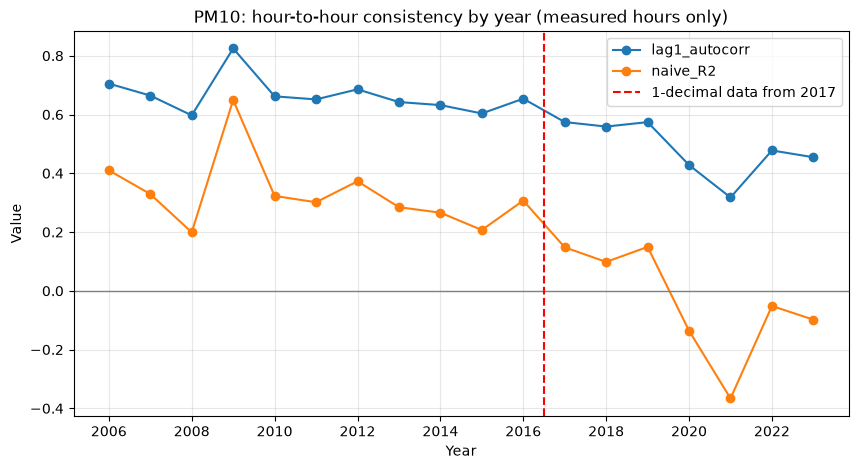

In [62]:
# is hourly PM10 getting noisier over the years?
from sklearn.metrics import r2_score

pm = wide["PM10"]

# naive baseline R² within each year: next hour = this hour
def naive_r2(x):
    d = pd.DataFrame({"now": x, "next": x.shift(-1)}).dropna()
    return r2_score(d["next"], d["now"])

yearly = pd.DataFrame({
    "hours_measured": pm.groupby(pm.index.year).count(),
    "lag1_autocorr": pm.groupby(pm.index.year).apply(lambda x: x.autocorr(1)),
    "mean_hourly_change": pm.diff().abs().groupby(pm.index.year).mean(),
    "naive_R2": pm.groupby(pm.index.year).apply(naive_r2),
})

# share of raw values recorded with 3+ decimal places (a sign of a processing change)
pm_raw = df_sel[df_sel["Parameter"] == "PM10"]
decimals = pm_raw["Value"].astype(str).str.split(".").str[1].str.len()
yearly["pct_3plus_decimals"] = (decimals >= 3).groupby(pm_raw["datetime"].dt.year).mean() * 100

display(yearly.round(2))

# chart: hour-to-hour consistency by year
yearly[["lag1_autocorr", "naive_R2"]].plot(marker="o", figsize=(10, 5))
plt.axhline(0, color="grey", linewidth=1)
plt.axvline(2016.5, color="red", linestyle="--", label="1-decimal data from 2017")
plt.title("PM10: hour-to-hour consistency by year (measured hours only)")
plt.xticks(range(2006, 2024, 2))  # whole years on the x-axis
plt.xlabel("Year")
plt.ylabel("Value")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [60]:
# remember which hours were really measured (before gap filling),
# so models can later be scored on measured hours only
import os
measured_flags = wide.notna()
measured_flags.to_csv("henderson_measured_flags.csv")
print("Saved:", os.path.abspath("henderson_measured_flags.csv"), measured_flags.shape)
print(measured_flags.mean().round(3))

Saved: C:\Users\suraj\Downloads\henderson_measured_flags.csv (150432, 5)
Parameter
NO2     0.878
PM10    0.956
RH      0.882
Temp    0.888
WS      0.895
dtype: float64


In [64]:
# mark which values are missing
na = wide.isna()

# length of each run of missing hours
gap_len = na.apply(lambda s: s.groupby((~s).cumsum()).transform("sum"))

# interpolate, then blank out anything inside a gap longer than 6 hours
wide_filled = wide.interpolate(method="time", limit_area="inside").mask(na & (gap_len > 6))

print("Before:", wide.isna().sum().sum())
print("After:", wide_filled.isna().sum().sum())
print(wide_filled.isna().sum())

Before: 75421
After: 68680
Parameter
NO2     14580
PM10     4153
RH      17549
Temp    16747
WS      15651
dtype: int64


In [70]:
# Create a forecasting dataset using only past observations
wide_model = wide.copy()

# Process each measurement column separately
for col in wide_model.columns:
    missing = wide_model[col].isna()

    # Identify consecutive missing-value groups
    groups = missing.ne(missing.shift()).cumsum()
    gap_lengths = missing.groupby(groups).transform("sum")

    # Fill gaps using earlier available observations only
    filled = wide_model[col].ffill(limit=6)

    # Keep gaps longer than six hours missing
    wide_model[col] = filled.mask(missing & (gap_lengths > 6))

# Save a separate forecasting dataset
wide_model.to_csv("henderson_model_no_future_interpolation.csv")

print("Forecasting dataset saved.")
print(wide_model.shape)
print(wide_model.isna().sum())

Forecasting dataset saved.
(150432, 5)
Parameter
NO2     14580
PM10     4153
RH      17549
Temp    16747
WS      15651
dtype: int64


In [74]:
# Compare historical interpolation with forward-only filling
difference = (
    wide_filled.fillna(-999999)
    != wide_model.fillna(-999999)
)

print("Number of values changed in each column:")
print(difference.sum())

Number of values changed in each column:
Parameter
NO2     3736
PM10    2416
RH       223
Temp     119
WS       147
dtype: int64


In [76]:
# hours around the biggest PM10 value
wide_filled.loc["2007-06-27 08:00":"2007-06-27 15:00", "PM10"]

# suspiciously low humidity
(wide_filled["RH"] < 10).sum()

np.int64(0)

In [78]:
# save clean data
# NEW (supervisor feedback): file now has the isolated PM10 spikes removed
import os
wide_filled.to_csv("henderson_clean_final_data.csv")
print("Saved:", os.path.abspath("henderson_clean_final_data.csv"), wide_filled.shape)

Saved: C:\Users\suraj\Downloads\henderson_clean_final_data.csv (150432, 5)
